# 10 — ABIDE I + ABIDE II: Apakah Data yang Lebih Banyak Menaikkan Akurasi?

> **Peran dalam alur.** Notebook ini adalah **pembuat** berkas FC (`data/processed/fitur_dcan_22/`: kovarians, korelasi, tangent per fold) dan hasil **baseline Logistic Regression** (`result/tabel/22_cache/C3_gab_tangent_<atlas>.npz`) yang dipakai skenario S1–S4. Penjelasan langkah demi langkah preprocessing rs-fMRI ada di **notebook 11**, dan baseline LR dijelaskan tersendiri di **notebook 14** (keduanya memverifikasi bahwa hasilnya identik dengan berkas dari notebook ini). Bagian C2 (PCP vs DCAN) dan C4 (lintas dataset) adalah percobaan pendukung yang tidak dipakai skenario. Notebook ini **tidak perlu dijalankan ulang**.

Kohort gabungan dari notebook 09 berisi **1.638 subjek** (886 ABIDE I + 752 ABIDE II, 34 situs), semuanya diolah dengan pipeline DCAN yang sama. Notebook ini menjawab tiga pertanyaan:

| Bagian | Pertanyaan | Desain |
| :---: | :--- | :--- |
| **C2** | Apakah pipeline DCAN sebaik pipeline PCP yang dipakai selama ini? | **ABIDE I saja**, subjek dan fold sama (886 subjek, `fold_abide1`): DCAN vs PCP |
| **C3** | Apakah menambah ABIDE II ke data latih menaikkan akurasi? | 5-fold gabungan (`fold_gabungan`). Perbandingan kuncinya: pada **subjek uji ABIDE I yang sama**, model dilatih dengan ABIDE I saja vs ABIDE I + II |
| **C4** | Apakah model bisa digeneralisasi ke dataset lain? | **latih di ABIDE I, uji di ABIDE II**, dan sebaliknya |

### Fitur dan penilai (sama dengan 09b/18/19)

- Time series DCAN 3 atlas (Gordon 352, HCP/Glasser 379, Markov 205 ROI). Frame dengan FD ≥ 0,3 mm dibuang memakai masker gerakan DCAN.
- Kovarians Ledoit-Wolf per subjek → **tangent space** (acuan = rata-rata geometrik kovarians **subjek latih** setiap pembagian) dan korelasi (Fisher z). Tangent dihitung dengan `src/tangent_cepat.py`: algoritma sama dengan nilearn, tetapi dekomposisi eigen dikerjakan per kelompok matriks dengan PyTorch (CPU, float64). Hasilnya **identik** dengan nilearn (selisih ~10⁻⁸ pada fitur bernilai ~10⁻²) dan ±3× lebih cepat.
- Logistic Regression L2 + standardisasi, `C` dipilih 3-fold di dalam data latih (skor AUC), satu model per atlas, lalu probabilitas dirata-rata.
- Tanpa harmonisasi situs (ComBat merugikan di 09b).

### Lama proses

Kovarians dihitung sekali per subjek (±15–30 menit), tangent untuk setiap pembagian ±1–1,5 jam, dan penilaian ±1 jam. Total **±2,5–3,5 jam**, CPU saja, dan **bisa dihentikan lalu dilanjutkan** (cache di `data/processed/fitur_dcan_22/` ±9 GB dan `result/tabel/22_cache/`). Sebaiknya dijalankan malam hari, tanpa notebook lain.

## 1. Persiapan

In [1]:
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import scipy.io
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.covariance import LedoitWolf
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from nilearn.connectome import sym_matrix_to_vec
from nilearn.connectome import connectivity_matrices as cmod
from IPython.display import display
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
from src.metrics import hitung_metrik
from src.tangent_cepat import rata_rata_geometrik, tangent as tangent_dari_kovarians

# ----- Parameter notebook -----
ATLAS = ["gordon2014", "hcp2016", "markov2012"]
ATLAS_PCP = ["aal", "harvard_oxford", "cc200", "cc400"]
FD_AMBANG = 0.3                 # sama dengan notebook 21
GRID_C = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]
BATAS_SUBJEK = None             # None = seluruh kohort (hanya diubah untuk uji coba)

PROC = ROOT / "data" / "processed"
FITUR_DIR = PROC / "fitur_dcan_22"
TANGENT_PCP = PROC / "fitur_tangent_09b"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR = ROOT / "result" / "figure"
CACHE_DIR = TABEL_DIR / "22_cache"
for d in (FITUR_DIR, TABEL_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
if BATAS_SUBJEK is not None:
    kohort = kohort.groupby("dataset", group_keys=False).sample(BATAS_SUBJEK // 2, random_state=42).sort_index().reset_index(drop=True)
akhiran = "" if BATAS_SUBJEK is None else f"_uji{BATAS_SUBJEK}"
y = kohort["label"].to_numpy()
ds = kohort["dataset"].to_numpy()
I1, I2 = np.where(ds == "abide1")[0], np.where(ds == "abide2")[0]
f_a1 = kohort["fold_abide1"].to_numpy()
f_gab = kohort["fold_gabungan"].to_numpy()
print(f"Subjek: {len(kohort)} (ABIDE I {len(I1)}, ABIDE II {len(I2)}) | ASD {y.sum()} | situs {kohort['situs'].nunique()}")

Subjek: 1638 (ABIDE I 886, ABIDE II 752) | ASD 714 | situs 34


## 2. Kovarians per Subjek (Sekali Saja)

Untuk setiap subjek dan atlas: time series CIFTI dibaca, frame dengan FD ≥ 0,3 mm dibuang (masker DCAN), lalu kovarians diestimasi dengan Ledoit-Wolf. Fitur **korelasi** (Fisher z) langsung diturunkan dari kovarians ini. Kovarians tidak bergantung fold, jadi aman dihitung untuk semua subjek.

In [2]:
def frame_dipakai(berkas_gerak):
    md_ = np.atleast_1d(scipy.io.loadmat(ROOT / berkas_gerak, squeeze_me=True, struct_as_record=False)["motion_data"])
    e = {round(float(x.FD_threshold), 2): x for x in md_}[FD_AMBANG]
    return np.asarray(e.frame_removal).astype(int) == 0

t0 = time.perf_counter()
COV = {}
for a in ATLAS:
    f_cov = FITUR_DIR / f"cov_{a}{akhiran}.npy"
    f_kor = FITUR_DIR / f"korelasi_{a}{akhiran}.npy"
    if f_cov.exists() and f_kor.exists():
        COV[a] = np.load(f_cov, mmap_mode="r")
        continue
    daftar = []
    for r in tqdm(kohort.to_dict("records"), desc=f"kovarians {a}"):
        ts = np.asarray(nib.load(ROOT / r[f"berkas_{a}"]).get_fdata(), dtype=np.float64)
        keep = frame_dipakai(r["berkas_gerak"])
        assert len(keep) == ts.shape[0], f"panjang masker != frame untuk {r['sub']}"
        daftar.append(LedoitWolf(store_precision=False).fit(ts[keep]).covariance_.astype(np.float32))
    C = np.stack(daftar)
    np.save(f_cov, C)
    d = np.sqrt(np.einsum("nii->ni", C))
    kor = C / (d[:, :, None] * d[:, None, :])
    np.save(f_kor, np.arctanh(np.clip(sym_matrix_to_vec(kor, discard_diagonal=True), -0.999999, 0.999999)).astype(np.float32))
    COV[a] = np.load(f_cov, mmap_mode="r")
    print(f"{a}: kovarians {C.shape} ({(time.perf_counter() - t0) / 60:.1f} menit berjalan)")
    del daftar, C, kor
print(f"Kovarians siap ({(time.perf_counter() - t0) / 60:.1f} menit; 0 berarti dari cache).")

kovarians gordon2014:   0%|          | 0/1638 [00:00<?, ?it/s]

gordon2014: kovarians (1638, 352, 352) (17.2 menit berjalan)


kovarians hcp2016:   0%|          | 0/1638 [00:00<?, ?it/s]

hcp2016: kovarians (1638, 379, 379) (27.3 menit berjalan)


kovarians markov2012:   0%|          | 0/1638 [00:00<?, ?it/s]

markov2012: kovarians (1638, 205, 205) (32.8 menit berjalan)
Kovarians siap (32.8 menit; 0 berarti dari cache).


## 3. Tangent Space untuk Setiap Pembagian

Acuan tangent (rata-rata geometrik) dihitung **hanya dari subjek latih** setiap pembagian:

| Pembagian | Subjek acuan | Dipakai di |
| :--- | :--- | :--- |
| `a1_k` (k = 0–4) | ABIDE I dengan `fold_abide1` ≠ k | C2, C3 (pembanding ABIDE I saja) |
| `gab_k` (k = 0–4) | semua subjek dengan `fold_gabungan` ≠ k | C3 |
| `i_ke_ii` | seluruh ABIDE I | C4 (latih ABIDE I, uji ABIDE II) |
| `ii_ke_i` | seluruh ABIDE II | C4 (latih ABIDE II, uji ABIDE I) |

In [3]:
PEMBAGIAN = {**{f"a1_{k}": I1[f_a1[I1] != k] for k in range(5)},
             **{f"gab_{k}": np.where(f_gab != k)[0] for k in range(5)},
             "i_ke_ii": I1, "ii_ke_i": I2}

def tangent(a, nama):
    berkas = FITUR_DIR / f"tangent_{a}_{nama}{akhiran}.npy"
    if berkas.exists():
        return np.load(berkas, mmap_mode="r")
    C = COV[a]
    acuan = rata_rata_geometrik(C[PEMBAGIAN[nama]], max_iter=10, tol=1e-7)     # sama dengan nilearn, versi batch
    np.save(berkas, tangent_dari_kovarians(C, acuan))
    return np.load(berkas, mmap_mode="r")

t0 = time.perf_counter()
for a in ATLAS:
    for nama in tqdm(PEMBAGIAN, desc=f"tangent {a}"):
        tangent(a, nama)
print(f"Tangent siap ({(time.perf_counter() - t0) / 60:.1f} menit; 0 berarti dari cache).")

tangent gordon2014:   0%|          | 0/12 [00:00<?, ?it/s]

tangent hcp2016:   0%|          | 0/12 [00:00<?, ?it/s]

tangent markov2012:   0%|          | 0/12 [00:00<?, ?it/s]

Tangent siap (53.2 menit; 0 berarti dari cache).


## 4. Penilai (Dikunci)

In [4]:
INNER = StratifiedKFold(3, shuffle=True, random_state=42)

def lr_prob(X, tr, te):
    gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                      {"logisticregression__C": GRID_C}, cv=INNER, scoring="roc_auc", n_jobs=1)
    gs.fit(np.asarray(X[tr]), y[tr])
    return gs.predict_proba(np.asarray(X[te]))[:, 1]

def cv_prob(nama, ambil_X, idx, fold):
    """Probabilitas out-of-fold untuk subjek idx (posisi di kohort) dengan pembagian fold[idx]. Disimpan ke cache."""
    berkas = CACHE_DIR / f"{nama}{akhiran}.npz"
    if berkas.exists():
        return np.load(berkas)["p"]
    p = np.full(len(kohort), np.nan)
    for k in sorted(np.unique(fold[idx])):
        tr, te = idx[fold[idx] != k], idx[fold[idx] == k]
        p[te] = lr_prob(ambil_X(int(k)), tr, te)
    np.savez(berkas, p=p)
    return p

def satu_prob(nama, X, tr, te):
    berkas = CACHE_DIR / f"{nama}{akhiran}.npz"
    if berkas.exists():
        return np.load(berkas)["p"]
    p = np.full(len(kohort), np.nan)
    p[te] = lr_prob(X, tr, te)
    np.savez(berkas, p=p)
    return p

def metrik(p, idx, fold=None):
    if fold is None:
        m = hitung_metrik(y[idx], p[idx]); return {k: v * 100 for k, v in m.items()}, 0.0
    df = pd.DataFrame([hitung_metrik(y[idx][fold[idx] == k], p[idx][fold[idx] == k]) for k in sorted(np.unique(fold[idx]))])
    return {k: df[k].mean() * 100 for k in df}, df["accuracy"].std(ddof=0) * 100

HASIL = []
def catat(bagian, nama, p, idx, fold=None):
    m, sd = metrik(p, idx, fold)
    HASIL.append({"Bagian": bagian, "Varian": nama, "n uji": len(idx), "Akurasi (%)": m["accuracy"], "SD": sd, "AUC (%)": m["auc"],
                  "Sensitivitas (%)": m["sensitivity"], "Spesifisitas (%)": m["specificity"]})
    print(f"[{bagian}] {nama:55s} n={len(idx):4d} ACC {m['accuracy']:.2f} ± {sd:.2f} | AUC {m['auc']:.2f}")

## 5. C2 — Pipeline DCAN vs PCP pada ABIDE I

Subjek: 886 subjek ABIDE I yang lolos QC DCAN. Fold: `fold_abide1` (sama dengan seluruh notebook sebelumnya). Fitur PCP diambil dari cache 09b (tangent 4 atlas, acuan dari data latih fold kohort).

In [5]:
kohort_final = pd.read_csv(PROC / "kohort_final.csv")
baris_pcp = kohort_final.reset_index().set_index("FILE_ID").loc[kohort.loc[I1, "FILE_ID"], "index"].to_numpy()

def X_pcp(a):
    def ambil(k):
        X = np.zeros((len(kohort), np.load(TANGENT_PCP / f"tangent_{a}_fold{k}.npy", mmap_mode="r").shape[1]), dtype=np.float32)
        X[I1] = np.load(TANGENT_PCP / f"tangent_{a}_fold{k}.npy", mmap_mode="r")[baris_pcp]
        return X
    return ambil

P = {}
P["C2_pcp"] = np.mean([cv_prob(f"C2_pcp_{a}", X_pcp(a), I1, f_a1) for a in ATLAS_PCP], axis=0)
P["C2_dcan_tangent"] = np.mean([cv_prob(f"C2_dcan_tangent_{a}", lambda k, a=a: tangent(a, f"a1_{k}"), I1, f_a1) for a in ATLAS], axis=0)
KOR = {a: np.load(FITUR_DIR / f"korelasi_{a}{akhiran}.npy", mmap_mode="r") for a in ATLAS}
P["C2_dcan_korelasi"] = np.mean([cv_prob(f"C2_dcan_korelasi_{a}", lambda k, a=a: KOR[a], I1, f_a1) for a in ATLAS], axis=0)
P["C2_pcp_dcan"] = (P["C2_pcp"] + P["C2_dcan_tangent"]) / 2
for n, ket in [("C2_pcp", "PCP tangent 4 atlas"), ("C2_dcan_tangent", "DCAN tangent 3 atlas"),
               ("C2_dcan_korelasi", "DCAN korelasi 3 atlas"), ("C2_pcp_dcan", "PCP + DCAN (rata-rata)")]:
    catat("C2 (ABIDE I)", ket, P[n], I1, f_a1)

[C2 (ABIDE I)] PCP tangent 4 atlas                                     n= 886 ACC 68.98 ± 3.10 | AUC 77.75
[C2 (ABIDE I)] DCAN tangent 3 atlas                                    n= 886 ACC 70.89 ± 4.69 | AUC 79.23
[C2 (ABIDE I)] DCAN korelasi 3 atlas                                   n= 886 ACC 71.05 ± 3.69 | AUC 78.09
[C2 (ABIDE I)] PCP + DCAN (rata-rata)                                  n= 886 ACC 71.78 ± 4.97 | AUC 80.33


## 6. C3 — Gabungan ABIDE I + II

Model dilatih pada data latih fold gabungan (subjek ABIDE I **dan** ABIDE II), lalu diuji pada data uji fold itu. Hasil dilaporkan untuk seluruh subjek uji, dan terpisah untuk subjek uji ABIDE I dan ABIDE II.

**Perbandingan kunci:** subjek uji ABIDE I di fold gabungan **sama persis** dengan subjek uji di C2 (fold ABIDE I tidak diubah). Jadi "C2 DCAN tangent" vs "C3 pada subjek ABIDE I" mengukur **pengaruh menambah ABIDE II ke data latih**, dengan data uji yang identik.

In [6]:
semua = np.arange(len(kohort))
P["C3_gabungan"] = np.mean([cv_prob(f"C3_gab_tangent_{a}", lambda k, a=a: tangent(a, f"gab_{k}"), semua, f_gab) for a in ATLAS], axis=0)
catat("C3 (gabungan)", "latih I+II, uji semua", P["C3_gabungan"], semua, f_gab)
catat("C3 (gabungan)", "latih I+II, uji ABIDE I", P["C3_gabungan"], I1, f_gab)
catat("C3 (gabungan)", "latih I+II, uji ABIDE II", P["C3_gabungan"], I2, f_gab)
catat("C3 (pembanding)", "latih ABIDE I saja, uji ABIDE I (= C2 DCAN)", P["C2_dcan_tangent"], I1, f_a1)

[C3 (gabungan)] latih I+II, uji semua                                   n=1638 ACC 73.23 ± 3.48 | AUC 81.35
[C3 (gabungan)] latih I+II, uji ABIDE I                                 n= 886 ACC 73.29 ± 4.06 | AUC 81.59
[C3 (gabungan)] latih I+II, uji ABIDE II                                n= 752 ACC 73.15 ± 3.45 | AUC 81.11
[C3 (pembanding)] latih ABIDE I saja, uji ABIDE I (= C2 DCAN)             n= 886 ACC 70.89 ± 4.69 | AUC 79.23


## 7. C4 — Generalisasi Lintas Dataset

Model dilatih pada **seluruh** satu dataset dan diuji pada dataset lainnya, yang situs, scanner, dan periode pengambilan datanya berbeda. Ini uji generalisasi yang paling ketat.

In [7]:
P["C4_i_ke_ii"] = np.nanmean([satu_prob(f"C4_i_ke_ii_{a}", tangent(a, "i_ke_ii"), I1, I2) for a in ATLAS], axis=0)
P["C4_ii_ke_i"] = np.nanmean([satu_prob(f"C4_ii_ke_i_{a}", tangent(a, "ii_ke_i"), I2, I1) for a in ATLAS], axis=0)
catat("C4 (lintas dataset)", "latih ABIDE I → uji ABIDE II", P["C4_i_ke_ii"], I2)
catat("C4 (lintas dataset)", "latih ABIDE II → uji ABIDE I", P["C4_ii_ke_i"], I1)
catat("C4 (pembanding)", "ABIDE II di dalam CV gabungan (C3)", P["C3_gabungan"], I2, f_gab)

per_situs = pd.DataFrame({"situs": kohort.loc[I2, "situs"].values, "y": y[I2], "p": P["C4_i_ke_ii"][I2]})
per_situs["benar"] = (per_situs["p"] >= 0.5).astype(int) == per_situs["y"]
tab_situs = per_situs.groupby("situs").agg(n=("y", "size"), ASD=("y", "sum"), akurasi=("benar", "mean"))
tab_situs["akurasi"] *= 100
display(tab_situs.round(1).sort_values("akurasi").style.set_caption("C4: akurasi per situs ABIDE II (model dilatih di ABIDE I)"))
tab_situs.to_csv(TABEL_DIR / f"22_c4_per_situs{akhiran}.csv")

[C4 (lintas dataset)] latih ABIDE I → uji ABIDE II                            n= 752 ACC 69.68 ± 0.00 | AUC 75.18
[C4 (lintas dataset)] latih ABIDE II → uji ABIDE I                            n= 886 ACC 68.74 ± 0.00 | AUC 75.92
[C4 (pembanding)] ABIDE II di dalam CV gabungan (C3)                      n= 752 ACC 73.15 ± 3.45 | AUC 81.11


,n,ASD,akurasi
situs,,,
ABIDEII-UCLA_1,2,1,50.000000
ABIDEII-EMC_1,32,15,56.200000
ABIDEII-IU_1,37,17,62.200000
ABIDEII-NYU_1,69,41,62.300000
ABIDEII-SDSU_1,55,32,63.600000
ABIDEII-ONRC_2,53,19,64.200000
ABIDEII-BNI_1,43,23,65.100000
ABIDEII-TCD_1,33,15,66.700000
ABIDEII-GU_1,55,23,67.300000


## 8. Ringkasan dan Uji Kebermaknaan

,Bagian,Varian,n uji,Akurasi (%),SD,AUC (%),Sensitivitas (%),Spesifisitas (%)
0,C2 (ABIDE I),PCP tangent 4 atlas,886,68.980000,3.100000,77.750000,54.070000,81.780000
1,C2 (ABIDE I),DCAN tangent 3 atlas,886,70.890000,4.690000,79.230000,61.140000,79.180000
2,C2 (ABIDE I),DCAN korelasi 3 atlas,886,71.050000,3.690000,78.090000,65.290000,75.620000
3,C2 (ABIDE I),PCP + DCAN (rata-rata),886,71.780000,4.970000,80.330000,58.980000,82.720000
4,C3 (gabungan),"latih I+II, uji semua",1638,73.230000,3.480000,81.350000,61.140000,82.520000
5,C3 (gabungan),"latih I+II, uji ABIDE I",886,73.290000,4.060000,81.590000,67.860000,77.920000
6,C3 (gabungan),"latih I+II, uji ABIDE II",752,73.150000,3.450000,81.110000,52.310000,87.520000
7,C3 (pembanding),"latih ABIDE I saja, uji ABIDE I (= C2 DCAN)",886,70.890000,4.690000,79.230000,61.140000,79.180000
8,C4 (lintas dataset),latih ABIDE I → uji ABIDE II,752,69.680000,0.000000,75.180000,50.160000,83.300000
9,C4 (lintas dataset),latih ABIDE II → uji ABIDE I,886,68.740000,0.000000,75.920000,47.900000,86.280000


,Perbandingan (A → B),Selisih akurasi (poin),Hanya benar di B,Hanya benar di A,p (McNemar),"Bermakna (p < 0,05)"
0,C2: PCP → DCAN (ABIDE I),1.920000,101,84,0.239400,tidak
1,C2: PCP → PCP + DCAN (ABIDE I),2.820000,73,48,0.028700,ya
2,C3: latih I saja → latih I+II (uji ABIDE I yang sama),2.480000,67,45,0.046700,ya
3,C4: ABIDE II di CV gabungan → latih I uji II,-3.460000,42,68,0.016700,ya


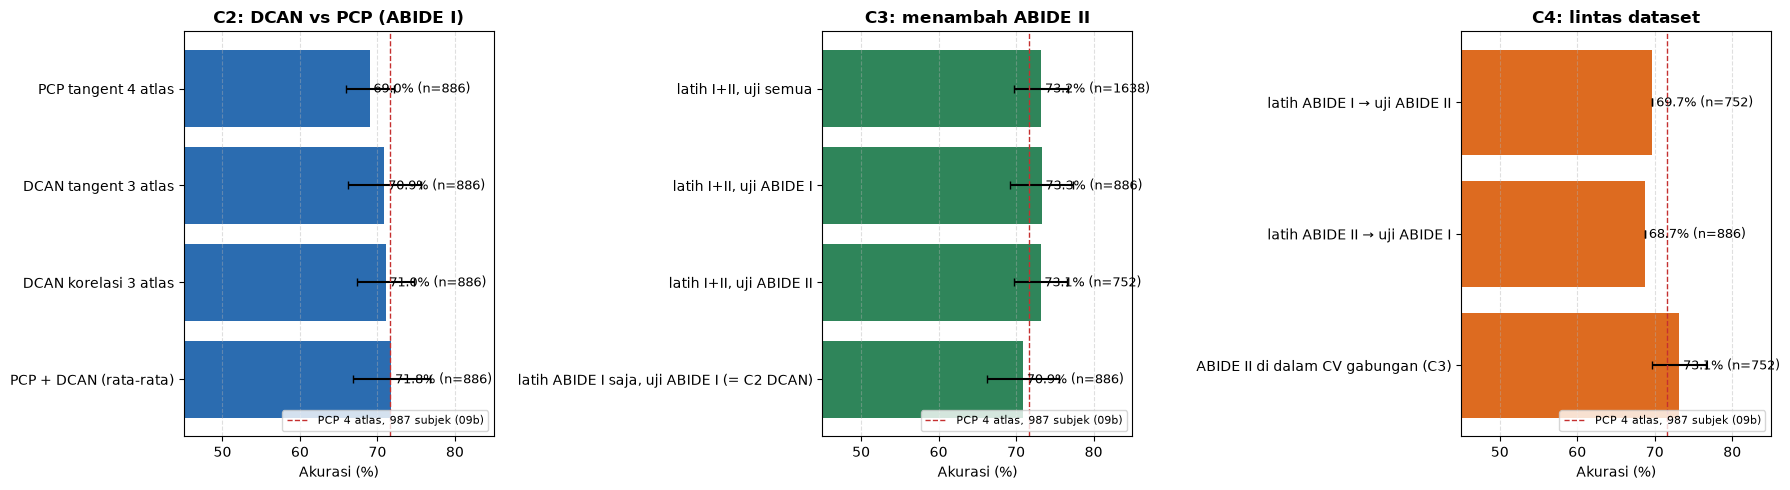

In [8]:
rekap = pd.DataFrame(HASIL)
display(rekap.round(2).style.set_caption("Ringkasan C2–C4"))
rekap.to_csv(TABEL_DIR / f"22_ringkasan{akhiran}.csv", index=False)

def mcnemar(pa, pb, idx):
    A, B = (pa[idx] >= 0.5).astype(int) == y[idx], (pb[idx] >= 0.5).astype(int) == y[idx]
    n01, n10 = int((~A & B).sum()), int((A & ~B).sum())
    return {"Selisih akurasi (poin)": round((B.mean() - A.mean()) * 100, 2), "Hanya benar di B": n01, "Hanya benar di A": n10,
            "p (McNemar)": round(stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0, 4)}

uji = pd.DataFrame([
    {"Perbandingan (A → B)": "C2: PCP → DCAN (ABIDE I)", **mcnemar(P["C2_pcp"], P["C2_dcan_tangent"], I1)},
    {"Perbandingan (A → B)": "C2: PCP → PCP + DCAN (ABIDE I)", **mcnemar(P["C2_pcp"], P["C2_pcp_dcan"], I1)},
    {"Perbandingan (A → B)": "C3: latih I saja → latih I+II (uji ABIDE I yang sama)", **mcnemar(P["C2_dcan_tangent"], P["C3_gabungan"], I1)},
    {"Perbandingan (A → B)": "C4: ABIDE II di CV gabungan → latih I uji II", **mcnemar(P["C3_gabungan"], P["C4_i_ke_ii"], I2)},
])
uji["Bermakna (p < 0,05)"] = np.where(uji["p (McNemar)"] < 0.05, "ya", "tidak")
display(uji.style.set_caption("Uji McNemar (subjek uji sama)"))
uji.to_csv(TABEL_DIR / f"22_uji_mcnemar{akhiran}.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, bagian, warna in [(axes[0], "C2", "#2B6CB0"), (axes[1], "C3", "#2F855A"), (axes[2], "C4", "#DD6B20")]:
    d = rekap[rekap["Bagian"].str.startswith(bagian)]
    ax.barh(d["Varian"], d["Akurasi (%)"], xerr=d["SD"], capsize=3, color=warna)
    for i, (v, n) in enumerate(zip(d["Akurasi (%)"], d["n uji"])):
        ax.text(v + 0.5, i, f"{v:.1f}% (n={n})", va="center", fontsize=9)
    ax.axvline(71.63, color="#C53030", ls="--", lw=1, label="PCP 4 atlas, 987 subjek (09b)")
    ax.set_xlim(45, 85); ax.set_xlabel("Akurasi (%)"); ax.invert_yaxis()
    ax.set_title({"C2": "C2: DCAN vs PCP (ABIDE I)", "C3": "C3: menambah ABIDE II", "C4": "C4: lintas dataset"}[bagian], fontweight="bold")
    ax.grid(axis="x", alpha=0.4, ls="--"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / f"22_1_abide1_abide2{akhiran}.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Cara Membaca Hasil

| Pertanyaan | Dilihat dari |
| :--- | :--- |
| Apakah DCAN sebaik PCP? | C2: PCP vs DCAN pada subjek dan fold yang sama. Kalau DCAN jauh lebih rendah, kenaikan dari ABIDE II bisa tertutup oleh pipeline yang lebih lemah |
| Apakah data lebih banyak membantu? | C3: "latih I saja" vs "latih I+II", **uji ABIDE I yang sama** (uji McNemar baris ketiga) |
| Apakah model berlaku di dataset lain? | C4: latih I → uji II. Penurunan dibanding ABIDE II di dalam CV gabungan menunjukkan besarnya perbedaan antar dataset |
| Situs mana yang sulit? | tabel akurasi per situs ABIDE II |

### Kesimpulan

*(Diisi setelah melihat hasil.)*